# MIS 205: INTRODUCTION TO PROGRAMMING

---

### Group Information

| Member Name | Student ID |
| :--- | :--- |
| Shahoriar Hossen Siam | ID-131-20-081 |
| M | ID-131-20-081 |
| M | ID-131-20-081 |
| M | ID-131-20-081 |
| M | ID-131-20-081 |



### Industry & Organisation

* **Industry:**
* **Organisation:** Airbnb
* **Identified Problem:**

### **YouTube API Data Collection Setup**

To fetch data from the YouTube Data API, we first obtained a Google Developer API key. Added it securely in Colab's secret manager under the key name `YOUTUBE_API_KEY`.

In [135]:
import os
import pandas as pd
import json
import re
from googleapiclient.discovery import build
from dotenv import load_dotenv

load_dotenv()


# Retrieve API key (with fallback to Colab secrets)
try:
    from google.colab import userdata
    api_key = userdata.get('YOUTUBE_API_KEY')
except Exception:
    api_key = os.getenv('YOUTUBE_API_KEY')


youtube = build('youtube', 'v3', developerKey=api_key)

query = "Airbnb"
print(f"API initialized. Search query set to: '{query}'")

API initialized. Search query set to: 'Airbnb'


### **Fetching the Data**
We will perform a search query to fetch videos related to our organisation, retrieve their statistics (Views, Likes, Comments).

In [136]:
# for cleaning shorts
def parse_duration_seconds(duration_str):
    """Parses ISO 8601 duration (e.g. 'PT5M30S', 'PT45S') to total seconds."""
    match = re.match(r'PT(?:(\d+)H)?(?:(\d+)M)?(?:(\d+)S)?', duration_str)
    if not match:
        return 0
    hours = int(match.group(1) or 0)
    minutes = int(match.group(2) or 0)
    seconds = int(match.group(3) or 0)
    return hours * 3600 + minutes * 60 + seconds





# function to fetch vides data with any query
def fetch_video_data(query, max_results=50):
    search_response = youtube.search().list(
        q=query,
        part='id,snippet',
        type='video',
        maxResults=max_results
    ).execute()

    video_ids = [item['id']['videoId'] for item in search_response['items']]

    stats_response = youtube.videos().list(
        part='statistics,snippet,contentDetails',
        id=','.join(video_ids)
    ).execute()


    data = []
    for item in stats_response['items']:

        duration_iso = item.get('contentDetails', {}).get('duration', '')
        duration_sec = parse_duration_seconds(duration_iso)
        # Skip videos under 60 seconds (Shorts)
        if duration_sec <= 60:
            continue



        # Extract metrics 
        video_id = item['id']
        title = item['snippet']['title']
        channel_name = item['snippet']['channelTitle']

        views = int(item['statistics'].get('viewCount', 0))
        likes = int(item['statistics'].get('likeCount', 0))
        comments = int(item['statistics'].get('commentCount', 0))

        data.append({
            'Video ID': video_id,
            'Video Title': title,
            'Channel Name': channel_name,
            'Views': views,
            'Likes': likes,
            'Comments': comments
        })
    
    return data


In [137]:
#call the function to get data and loadinto a dataframe
video_data = fetch_video_data(query) 
df = df = pd.DataFrame(video_data)
df.head(10)

,Video ID,Video Title,Channel Name,Views,Likes,Comments
0,Q3jXWW3nMxY,Airbnb introduces new cleaning rules to lessen...,NBC News,87040,513,314
1,Ax-dILXMvfA,Airbnb tour after a guest checkout #airbnb #ai...,Preksha Chand,228955,2599,84
2,9ZXzsjeRtdk,I Tried Every Airbnb Category,Ryan Trahan,28935245,449347,17978
3,hQfESv-zDD0,I Stayed in World’s MOST EXPENSIVE Airbnb,The Royalty Family,30316438,148927,12447
4,fBViwSXF2XE,New Airbnb rule says guests don’t have to clea...,Te-Erika,755,0,10
5,xyIF9hoNGqU,I Stayed in Every State's Top Ranked Airbnb,Ryan Trahan,21868827,159974,6864
6,wmpTu8sTImQ,Airbnb Changes Leaves Hosts Angry,penguinz0,2362084,45077,6087
7,NF7y66SAT9o,I Tested the World’s Most Extreme Airbnbs,Addie Bowley,2902812,42467,2238
8,f6uKw7mf4XQ,Cheapest vs Most Expensive Airbnb,Nishu Tiwari,5147845,145810,4418
9,AHrCkEkXqVk,I Stayed in the World's Weirdest Airbnbs,drewdoes,591986,6082,183


### **Simple Analysis**



#### Calculations

- Total Views
- Average Views
- Averatge Likes
- Average Comments

In [138]:
# Total Views
print("Total Views: ", df['Views'].sum())

# Average Views
print("Average Views: ", df['Views'].sum()/df.shape[0])

# Average Likes
print("Average Likes: ", df['Likes'].sum()/df.shape[0])

# Average Comments
print("Average Comments: ", df['Comments'].sum()/df.shape[0])

Total Views:  206322321
Average Views:  5429534.763157895
Average Likes:  85553.81578947368
Average Comments:  3016.0263157894738


#### Finds

- Most liked video
- Most viewed video
- Top 5 videos

In [139]:
print("Most viewed video:")
print(df.loc[df['Views'].idxmax()])

print("-"*43)

print("Most Liked video:")
print(df.loc[df['Likes'].idxmax()])

print("-"*43)

print("Top 5 videos by views:")
print(df.sort_values("Views", ascending=False).head(5))


Most viewed video:
Video ID                       Dcp02c9LLEw
Video Title     I Stayed in “OMG!” Airbnbs
Channel Name                   Ryan Trahan
Views                             41269941
Likes                               610250
Comments                             33526
Name: 13, dtype: object
-------------------------------------------
Most Liked video:
Video ID                                       sAF2ffEnc24
Video Title     Craziest things left behind in our Airbnb!
Channel Name                                 Kaiser Martin
Views                                             22001871
Likes                                               636037
Comments                                              4450
Name: 32, dtype: object
-------------------------------------------
Top 5 videos by views:
       Video ID                                  Video Title  \
13  Dcp02c9LLEw                   I Stayed in “OMG!” Airbnbs   
3   hQfESv-zDD0    I Stayed in World’s MOST EXPENSIVE Airbnb   


#### Views vs Likes vs Comments

**Just for Fun** :))

/tmp/ipykernel_2376521/743246555.py:26: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/calibur/codes/205-project/.venv/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 10060 (\N{CROSS MARK}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


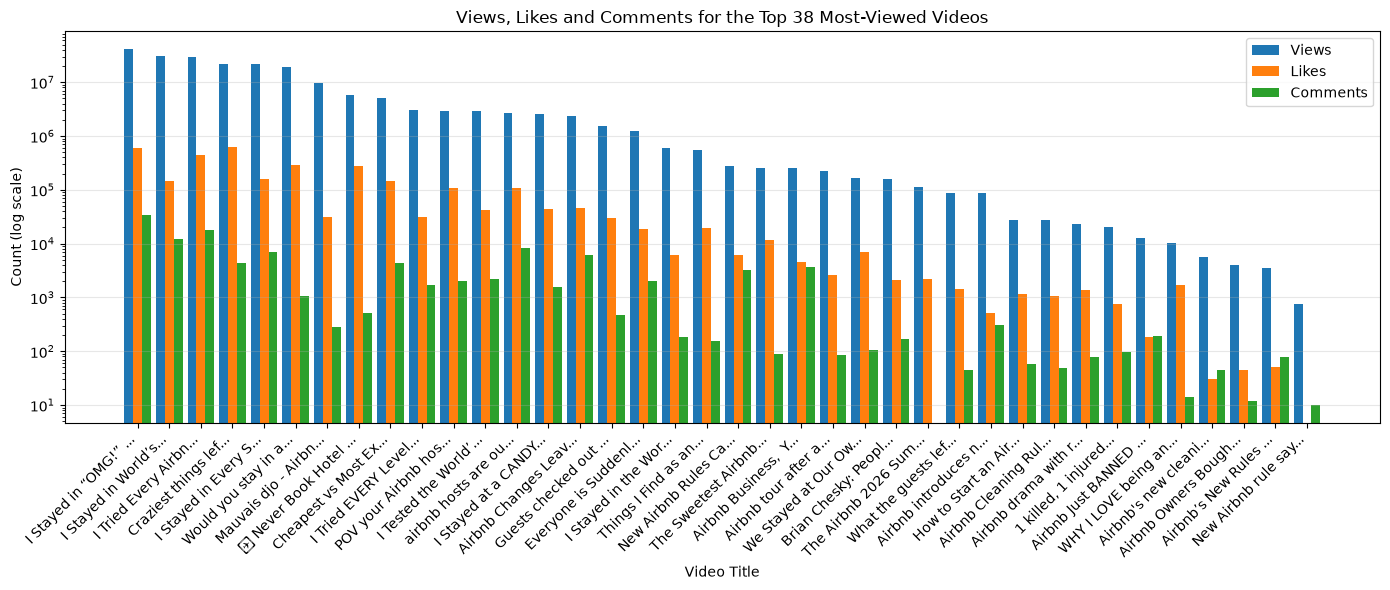

In [140]:
import matplotlib.pyplot as plt
import numpy as np

plot_df = df.sort_values("Views", ascending=False).head(50).copy()
plot_df["Short Title"] = plot_df["Video Title"].apply(
    lambda t: t if len(t) <= 22 else t[:19] + "..."
)

x = np.arange(len(plot_df))   
width = 0.28               

fig, ax = plt.subplots(figsize=(14, 6))

ax.bar(x - width, plot_df["Views"],    width, label="Views",    color="#1f77b4")
ax.bar(x,         plot_df["Likes"],    width, label="Likes",    color="#ff7f0e")
ax.bar(x + width, plot_df["Comments"], width, label="Comments", color="#2ca02c")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["Short Title"], rotation=45, ha="right")
ax.set_xlabel("Video Title")
ax.set_ylabel("Count (log scale)")
ax.set_title(f"Views, Likes and Comments for the Top {len(plot_df)} Most-Viewed Videos")
ax.set_yscale("log")   # log scale so Likes/Comments stay readable next to Views
ax.grid(axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()


### **Analysis and Visualizations**


#### Trend Analysis: Views & Engagement by Year (2016–2026)

To see how interest in Airbnb has changed over time, we collected the **top 20 most-viewed videos published in each year from 2016 to 2026** (Shorts under 60 seconds are filtered out). For each video we recorded views, likes, comments and publish date, and derive two extra fields:


* **Engagement Rate (%)** = `(Likes + Comments) / Views × 100` — how much interaction a view produced.
* **Views per Day** = `Views / days since publish`


*The raw data is cached to `youtube_trends_2016_2026.csv` so the notebook does not use API quota on every run.*


In [141]:
import matplotlib.pyplot as plt
import numpy as np

# Collect 20 videos per year, 2016-2026
TREND_QUERY = query
YEARS = range(2016, 2027)
VIDEOS_PER_YEAR = 20
CACHE_FILE = "youtube_trends_2016_2026.csv"


# we are gonna fetch 50 videos and get tops after filtering
def fetch_videos_for_year(year, query=TREND_QUERY, videos_per_year=VIDEOS_PER_YEAR, pool=50):
    """Top `per_year` non-Shorts videos published in `year`, with statistics."""
    search = youtube.search().list(
        q=query,
        part="id",
        type="video",
        order="viewCount",          # top videos of that year
        maxResults=pool,
        publishedAfter=f"{year}-01-01T00:00:00Z",
        publishedBefore=f"{year}-12-31T23:59:59Z",
    ).execute()


    # get the ids of the vidoes
    video_ids = []
    for item in search.get("items", []):
        video_id = item["id"].get("videoId")
        video_ids.append(video_id)

    # cleaning if there is any playlist or channels
    cleaned_ids = []
    for vid in video_ids:
        if vid:  # only keep if vid is not None and not empty
            cleaned_ids.append(vid)
    video_ids = cleaned_ids
    video_ids = ",".join(video_ids)



    stats = youtube.videos().list(
        part="statistics,snippet,contentDetails",
        id=video_ids,
    ).execute()



    video_rows = []
    for item in stats.get("items", []):
        duration = parse_duration_seconds(item.get("contentDetails", {}).get("duration", ""))
        if duration <= 60:          # skip Shorts
            continue

        st = item.get("statistics", {})
        views = int(st.get("viewCount", 0) or 0)
        likes = int(st.get("likeCount", 0) or 0)
        comments = int(st.get("commentCount", 0) or 0)
        if views == 0:  #if for some reason there a video with ZeRo views
            continue

        published = pd.to_datetime(item["snippet"]["publishedAt"]).tz_localize(None)
        age_days = max((pd.Timestamp.now() - published).days, 1)

        video_rows.append({
            "Year": year,
            "Video ID": item["id"],
            "Video Title": item["snippet"]["title"],
            "Channel Name": item["snippet"]["channelTitle"],
            "Published": published,
            "Duration (s)": duration,
            "Views": views,
            "Likes": likes,
            "Comments": comments,
            "Engagement Rate (%)": (likes + comments) / views * 100,
            "Views per Day": views / age_days,
        })
        if len(video_rows) == videos_per_year:
            break

    return pd.DataFrame(video_rows)


if os.path.exists(CACHE_FILE):
    trend_df = pd.read_csv(CACHE_FILE, parse_dates=["Published"])
    print(f"Loaded {len(trend_df)} videos from cache: {CACHE_FILE}")
else:
    frames = []
    for year in YEARS:
        part = fetch_videos_for_year(year)
        frames.append(part)
        print(f"{year}: {len(part)} videos")
    print(frames)
    trend_df = pd.concat(frames, ignore_index=True)
    trend_df.to_csv(CACHE_FILE, index=False)
    print(f"\nSaved {len(trend_df)} videos to {CACHE_FILE}")

print("\nVideos per year:")
print(trend_df["Year"].value_counts().sort_index().to_string())
trend_df.head()

Loaded 220 videos from cache: youtube_trends_2016_2026.csv

Videos per year:
Year
2016    20
2017    20
2018    20
2019    20
2020    20
2021    20
2022    20
2023    20
2024    20
2025    20
2026    20


,Year,Video ID,Video Title,Channel Name,Published,Duration (s),Views,Likes,Comments,Engagement Rate (%),Views per Day
0,2016,oGLe0Wgfbyk,Why Your Airbnb May Be ILLEGAL | Adam Ruins Ev...,Dropout,2016-10-05 16:30:00,352,8017239,125747,5112,1.632220,2183.938709
1,2016,OXVRB_u9Y7M,Community Commitment | Airbnb,Airbnb,2016-12-13 20:26:09,75,2314857,397,32,0.018532,642.658801
2,2016,ZSIhEbD6hpQ,最高のLA旅行！Airbnbで知らない人の家に泊まってみた☆ 〔#496〕,バイリンガール英会話 | Bilingirl Chika,2016-12-14 08:37:38,812,1236263,22858,706,1.906067,343.311025
3,2016,m3ZVWt38nC4,Why Airbnb Is Terrible - Cracked Explains,Cracked,2016-08-02 11:30:00,1037,1189764,19518,2848,1.879869,318.544578
4,2016,n0eTLdQ1cQc,Adam Ruins Everything - Why Your Airbnb May Be...,truTV,2016-10-08 13:58:01,343,778162,8073,461,1.096687,212.148855


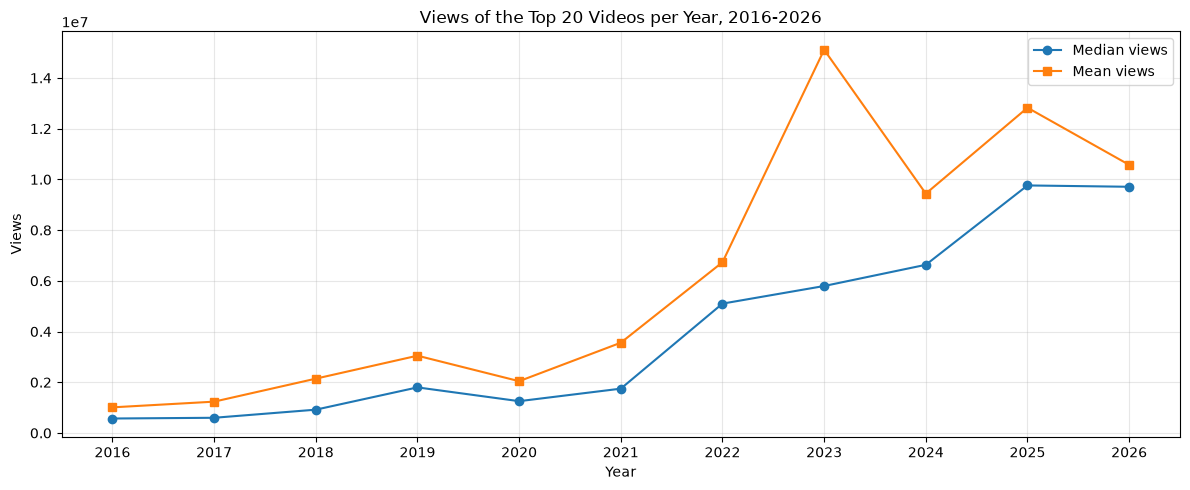

In [142]:
# chart 1: Views over time
grouped = trend_df.groupby("Year")["Views"]
median_views = grouped.median()
mean_views   = grouped.mean()

yearly_stats = pd.DataFrame({
    "median_views": median_views,
    "mean_views": mean_views
})

plt.figure(figsize=(12, 5))

plt.plot(yearly_stats.index, yearly_stats["median_views"], marker="o", label="Median views")
plt.plot(yearly_stats.index, yearly_stats["mean_views"], marker="s", label="Mean views")


plt.xticks(yearly_stats.index)
plt.xlabel("Year")
plt.ylabel("Views")
plt.title("Views of the Top 20 Videos per Year, 2016-2026")
plt.grid(alpha=0.3)
plt.legend()


plt.tight_layout()
plt.show()


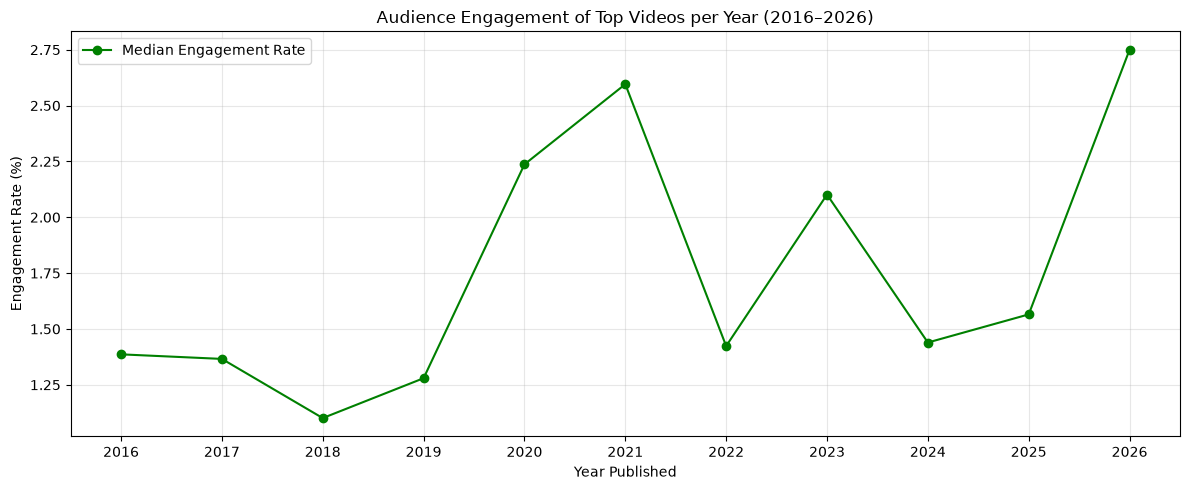

In [143]:
# Chart 2: Median Engagement Over Time
grouped_eng = trend_df.groupby("Year")["Engagement Rate (%)"]
median_eng = grouped_eng.median()

plt.figure(figsize=(12, 5))

plt.plot(median_eng.index, median_eng.values, marker="o", color="green", label="Median Engagement Rate")

plt.xticks(median_eng.index)
plt.xlabel("Year Published")
plt.ylabel("Engagement Rate (%)")
plt.title("Audience Engagement of Top Videos per Year (2016–2026)")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


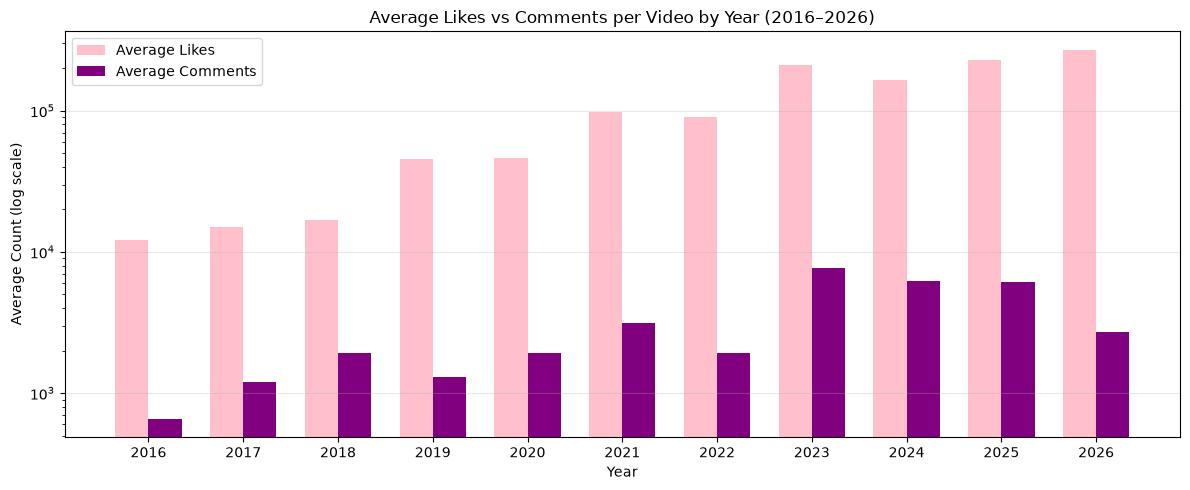

In [144]:
# Chart 3: Likes vs Comments by Year
avg = trend_df.groupby("Year")[["Likes", "Comments"]].mean()
years = avg.index
width = 0.35

plt.figure(figsize=(12, 5))


plt.bar(years - width/2, avg["Likes"], width=width, label="Average Likes", color="pink")
plt.bar(years + width/2, avg["Comments"], width=width, label="Average Comments", color="purple")


plt.yscale("log")              # Log scale because likes are much larger than comments
plt.xticks(years)
plt.xlabel("Year")
plt.ylabel("Average Count (log scale)")
plt.title("Average Likes vs Comments per Video by Year (2016–2026)")
plt.grid(axis="y", alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


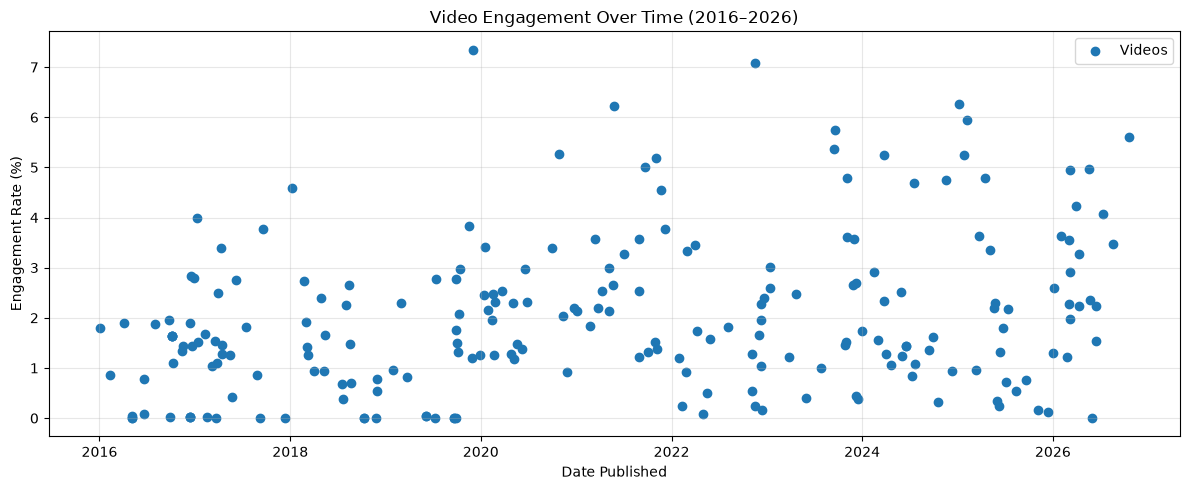

In [145]:
# Chart 4: Engagement over time, linear
plt.figure(figsize=(12, 5))

plt.scatter(trend_df["Published"], trend_df["Engagement Rate (%)"], label="Videos")

plt.xlabel("Date Published")
plt.ylabel("Engagement Rate (%)")
plt.title("Video Engagement Over Time (2016–2026)")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()


### **Conclusion**



#### Key findings


#### Possible solutions

#### Interpretation & recommendation


??